# Reproducing "How Stale Is Too Stale?"

This notebook recomputes every number in the paper from the records in `results/` and
checks each one against the value printed in the paper. A line marked `ok` means the
recomputed value, rounded as the paper rounds it, equals the printed value. The last cell
counts the checks and fails if any did not match.

**What it needs.** Python 3.10 or later with `numpy`, `pytest` and `matplotlib`. The records
are small (about 14 MB) and the default run takes well under a minute.

**What it does not do by default.** The records were produced by `code/analysis/rpki/rov_unit.py`
from public archives (RIPE RIS RIB dumps, the RIPE NCC daily RPKI archive and RPKIViews
snapshots). Section 13 reruns one reference day from those archives when `RUN_RAW = True`.
That downloads about 1.3 GB, needs about 1.5 GiB of memory and takes about 30 minutes.

Sections follow the paper: preregistered checks and bars (Method, Sections IV and V),
the table and figure, who is exposed, persistence, attribution, and the earlier payload-list test.

In [1]:
RUN_RAW = False          # set True to rerun one reference day from the public archives (Section 13)

import ast, json, re, subprocess, sys, statistics
from collections import Counter, defaultdict
from datetime import date, datetime, timedelta, timezone
from pathlib import Path

import numpy as np

ROOT = Path.cwd()
CODE, RES = ROOT / "code", ROOT / "results"
assert (CODE / "analysis" / "rpki" / "rov.py").exists(), "run this notebook from the repository root"
sys.path[:0] = [str(CODE / "analysis" / "rpki"), str(CODE), str(CODE / "paper")]

import run_sealed_rov as G                      # the sealed grader: constants and helpers
from rov_unit import GRADED_T0, DAILY_DELTAS, SUBDAY_DELTAS

def load(p): return json.loads(Path(p).read_text())

U = [load(RES / "graded" / f"rov-unit-{t.isoformat()}.json") for t in GRADED_T0]   # sealed inputs
S916 = load(RES / "sensitivity-0916" / "rov-unit-2026-09-16.json")                  # 16 Sep from complete dumps
SENS = [S916 if u["t0"] == "2026-09-16" else u for u in U]
V = load(RES / "rpki-rov-staleness.json")                                           # the graded verdict
VS = load(RES / "rpki-rov-staleness.sens-0916-complete-rib.json")                   # the sensitivity regrade
ATT = {r["t0"]: r for r in map(load, sorted((RES / "ungraded-v2").glob("rov-ungraded-attrib-*.json")))}
PER = [load(p) for p in sorted((RES / "ungraded-v2").glob("rov-ungraded-persist-*.json"))]
print(len(U), "graded days,", len(ATT), "attribution records,", len(PER), "persistence records")

CHECKS = []
def check(label, computed, paper, tol=None):
    ok = (computed == paper) if tol is None else abs(computed - paper) <= tol
    CHECKS.append((label, ok))
    print(f"{'ok      ' if ok else 'MISMATCH'} {label}: computed {computed!r}, paper {paper!r}")

def pct(x, nd):   # a fraction as a percentage rounded to nd decimals
    return round(100 * x, nd)

8 graded days, 8 attribution records, 19 persistence records


## 1. Manipulation checks (Method, "Validator and input checks")

MC1 input floors, MC2 the planted validator tests (`test_rpki_rov.py`, byte-identical to the sealed file), MC3 the Routinator cross-check, MC4 the
bridge between the two archives. Each is recomputed from the records, and MC2 is rerun.

In [2]:
mc1 = []
for u in U:
    for c, s in u["rib"].items():
        if s["distinct_pairs"] <= 500_000: mc1.append((u["t0"], c))
    for per in [u["daily_fresh"]["per_ta"]] + [r["stale_per_ta"] for r in u["daily"].values()]:
        mc1 += [(u["t0"], t) for t, n in per.items() if not t.endswith("_last_modified") and n <= 1000]
check("MC1 failures", len(mc1), 0)

p = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", str(CODE / "tests" / "test_rpki_rov.py")],
                   capture_output=True, text=True, cwd=CODE)
print(p.stdout.strip().splitlines()[-1])
check("MC2 planted tests pass", p.returncode, 0)
check("MC2 planted test count", int(re.search(r"(\d+) passed", p.stdout).group(1)), 17)
q = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", str(CODE / "tests" / "test_rov_ungraded.py")],
                   capture_output=True, text=True, cwd=CODE)
print("post-seal tests for the ungraded reports:", q.stdout.strip().splitlines()[-1])
check("post-seal tests pass", q.returncode, 0)

mc3 = load(RES / "rpki-rov-mc3.json")
check("MC3 announcements compared", mc3["n"], 1_439_978)
check("MC3 announcements disagreeing", mc3["routes_disagreeing"], 0)
check("MC3 Routinator version", mc3["image"], "nlnetlabs/routinator:v0.15.2")

mc4 = max(abs(u["daily_fresh"]["states"][s] - u["subday_fresh"]["states"][s]) / u["n"]
          for u in U for s in u["daily_fresh"]["states"])
check("MC4 largest outcome-count difference (%)", pct(mc4, 4), 0.0067)

ok       MC1 failures: computed 0, paper 0


17 passed in 0.06s
ok       MC2 planted tests pass: computed 0, paper 0
ok       MC2 planted test count: computed 17, paper 17


post-seal tests for the ungraded reports: 3 passed in 0.10s
ok       post-seal tests pass: computed 0, paper 0
ok       MC3 announcements compared: computed 1439978, paper 1439978
ok       MC3 announcements disagreeing: computed 0, paper 0
ok       MC3 Routinator version: computed 'nlnetlabs/routinator:v0.15.2', paper 'nlnetlabs/routinator:v0.15.2'
ok       MC4 largest outcome-count difference (%): computed 0.0067, paper 0.0067


## 2. The preregistered bars (Sections IV and V)

B1 and B2 (both errors grow, thirty-day value above one-day by more than four standard errors),
B3 (daily refresh, upper 95% bootstrap bound of the one-day to thirty-day ratio at most 10%),
B4 (sub-day arm). Recomputed with the grader's own helpers, seed and resample count, and compared
both with the sealed verdict record and with the paper.

In [3]:
def grade(units):
    acc = {d: np.array([u["daily"][str(d)]["e_accept"] for u in units]) for d in DAILY_DELTAS}
    drp = {d: np.array([u["daily"][str(d)]["e_drop"] for u in units]) for d in DAILY_DELTAS}
    out = {}
    for name, s in (("B1", acc), ("B2", drp)):
        means = [float(s[d].mean()) for d in DAILY_DELTAS]
        gain, se = G._paired(s[1], s[30])
        out[name] = {"means": means, "z": gain / se,
                     "pass": G._increasing(means, strict=True) and gain > G.SE_BAR * se}
    rng = np.random.default_rng(G.SEED)
    k, ratios = len(units), []
    for _ in range(G.BOOT):
        idx = rng.integers(0, k, k)
        m30 = acc[30][idx].mean()
        ratios.append(acc[1][idx].mean() / m30 if m30 > 0 else np.inf)
    upper = float(np.percentile(ratios, 95))
    out["B3"] = {"point": float(acc[1].mean() / acc[30].mean()), "upper": upper, "pass": upper <= G.B3_RATIO}
    sub = {lab: np.array([u["subday"][lab]["e_accept"] for u in units]) for lab in SUBDAY_DELTAS}
    smeans = [float(sub[lab].mean()) for lab in SUBDAY_DELTAS]
    sgain, sse = G._paired(sub["1h"], sub["1d"])
    out["B4"] = {"means": smeans, "z": sgain / sse,
                 "pass": G._increasing(smeans, strict=False) and sgain > G.SE_BAR * sse}
    out["verdict"] = "PASS" if all(out[b]["pass"] for b in ("B1", "B2", "B3")) else "FAIL"
    return out

B = grade(U)
check("verdict", B["verdict"], "FAIL")
check("verdict equals the sealed record", B["verdict"], V["verdict"])
for b in ("B1", "B2", "B3", "B4"):
    check(f"{b} pass/fail equals the sealed record", B[b]["pass"], V["bars"][b]["pass"])
check("B3 upper bound equals the sealed record exactly", B["B3"]["upper"], V["bars"]["B3"]["ratio_upper95"])
check("B1 gain in standard errors", round(B["B1"]["z"], 1), 5.8)
check("B2 gain in standard errors", round(B["B2"]["z"]), 32)
check("B3 point ratio (%)", pct(B["B3"]["point"], 1), 7.9)
check("daily refresh removes (%)", round(100 - 100 * B["B3"]["point"]), 92)
check("B3 upper 95% bound (%)", pct(B["B3"]["upper"], 1), 10.5)
check("B4 gain in standard errors", round(B["B4"]["z"], 1), 5.2)

ok       verdict: computed 'FAIL', paper 'FAIL'
ok       verdict equals the sealed record: computed 'FAIL', paper 'FAIL'
ok       B1 pass/fail equals the sealed record: computed True, paper True
ok       B2 pass/fail equals the sealed record: computed True, paper True
ok       B3 pass/fail equals the sealed record: computed False, paper False
ok       B4 pass/fail equals the sealed record: computed True, paper True
ok       B3 upper bound equals the sealed record exactly: computed 0.10512795502719177, paper 0.10512795502719177
ok       B1 gain in standard errors: computed 5.8, paper 5.8
ok       B2 gain in standard errors: computed 32, paper 32
ok       B3 point ratio (%): computed 7.9, paper 7.9
ok       daily refresh removes (%): computed 92, paper 92
ok       B3 upper 95% bound (%): computed 10.5, paper 10.5
ok       B4 gain in standard errors: computed 5.2, paper 5.2


## 3. Table I and Fig. 2

`code/paper/make_figs.py` builds the paper's table and figure from the eight graded records.
Here it regenerates both, the table is compared with the copy typeset in the paper
(`results/paper-figs/`), and the figure is drawn with matplotlib.

ok       Table I identical to the typeset table: computed '% generated by make_figs.py from the graded unit records\n\\begin{tabular}{@{}lrrrr@{}}\n\\toprule\nage & wrong accepts & removed & peer-weighted & wrong drops \\\\\n    & \\% (SE)       & \\% of accepts & \\% (SE) & \\% (SE) \\\\\n\\midrule\n1 d & 0.00464 (0.00083) & 84 & 0.00113 (0.00011) & 0.0196 (0.0064) \\\\\n2 d & 0.0103 (0.0017) & 71 & 0.00151 (0.00017) & 0.0359 (0.0041) \\\\\n4 d & 0.0120 (0.0027) & 81 & 0.00160 (0.00018) & 0.0476 (0.0027) \\\\\n8 d & 0.0355 (0.0096) & 72 & 0.00258 (0.00039) & 0.143 (0.011) \\\\\n15 d & 0.0458 (0.0099) & 73 & 0.00301 (0.00054) & 0.268 (0.017) \\\\\n30 d & 0.0590 (0.0096) & 76 & 0.00315 (0.00020) & 0.528 (0.013) \\\\\n\\midrule\n1h & 0.0000602 (0.000024) & 86 & 0.0000180 (0.000011) & 0.000491 (0.00024) \\\\\n6h & 0.00103 (0.00027) & 78 & 0.000244 (0.000077) & 0.00327 (0.0013) \\\\\n1d & 0.00429 (0.00083) & 82 & 0.000593 (0.00011) & 0.0215 (0.0067) \\\\\n\\bottomrule\n\\end{tabular}', pap

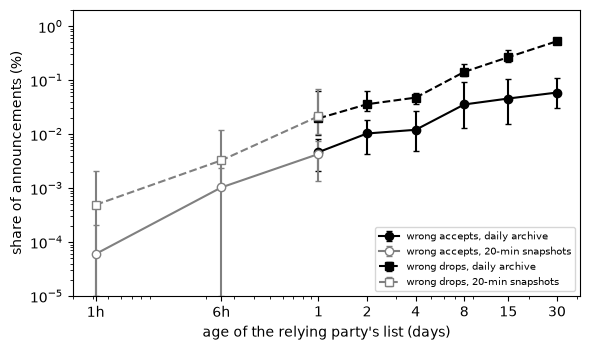

In [4]:
import make_figs
table = make_figs.table(U)
check("Table I identical to the typeset table", table.strip(), (RES / "paper-figs" / "table.tex").read_text().strip())
print(table)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 3.6))
xs = DAILY_DELTAS
for metric, style, lab in (("e_accept", "o-", "wrong accepts"), ("e_drop", "s--", "wrong drops")):
    vals = np.array([[u["daily"][str(d)][metric] * 100 for d in xs] for u in U])
    m = vals.mean(0)
    ax.errorbar(xs, m, yerr=[m - np.maximum(vals.min(0), 1e-5), vals.max(0) - m], fmt="k" + style,
                mfc="k", label=lab + ", daily archive", capsize=2)
    sx = [1 / 24, 6 / 24, 1]
    svals = np.array([[u["subday"][l][metric] * 100 for l in SUBDAY_DELTAS] for u in U])
    sm = svals.mean(0)
    ax.errorbar(sx, sm, yerr=[sm - np.maximum(svals.min(0), 1e-5), svals.max(0) - sm], fmt=style,
                color="gray", mfc="white", label=lab + ", 20-min snapshots", capsize=2)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(1e-5, 2)
ax.set_xticks([1 / 24, 6 / 24, 1, 2, 4, 8, 15, 30]); ax.set_xticklabels(["1h", "6h", "1", "2", "4", "8", "15", "30"])
ax.set_xlabel("age of the relying party's list (days)"); ax.set_ylabel("share of announcements (%)")
ax.legend(fontsize=7, loc="lower right"); plt.tight_layout(); plt.show()

## 4. Headline numbers (abstract, introduction, Section IV)

In [5]:
def mean_rate(arm, lab, key): return float(np.mean([u[arm][lab][key] for u in U]))
def counts(arm, lab, key, units=U): return [u[arm][lab][key] for u in units]
n_mean = np.mean([u["n"] for u in U])
check("announcements in the table (millions)", round(n_mean / 1e6, 2), 1.45)
inv = [u["daily_fresh"]["states"]["invalid"] / u["n"] for u in U]
check("Invalid share against a current list (%)", pct(np.mean(inv), 2), 0.76)
check("Invalid share, lowest day (%)", pct(min(inv), 2), 0.70)
check("Invalid share, highest day (%)", pct(max(inv), 2), 0.85)

check("wrong accepts at 1 d (%)", pct(mean_rate("daily", "1", "e_accept"), 4), 0.0046)
check("wrong accepts at 30 d (%)", pct(mean_rate("daily", "30", "e_accept"), 3), 0.059)
check("wrong drops at 1 d (%)", pct(mean_rate("daily", "1", "e_drop"), 3), 0.020)
check("wrong drops at 30 d (%)", pct(mean_rate("daily", "30", "e_drop"), 2), 0.53)
check("wrong accepts at 1 d, routes in the table", round(np.mean(counts("daily", "1", "accept")), -1), 70)
check("wrong accepts at 30 d, routes in the table", round(np.mean(counts("daily", "30", "accept")), -1), 860)
check("wrong drops at 1 d, routes in the table", round(np.mean(counts("daily", "1", "drop")), -1), 280)
check("wrong drops at 30 d, routes in the table", round(np.mean(counts("daily", "30", "drop")), -2), 7700)
check("abstract: one wrong drop in N at 30 d", round(1 / mean_rate("daily", "30", "e_drop"), -2), 200)
check("abstract: one wrong accept in N at 30 d", round(1 / mean_rate("daily", "30", "e_accept"), -2), 1700)
ratio = [mean_rate("daily", str(d), "e_drop") / mean_rate("daily", str(d), "e_accept") for d in DAILY_DELTAS]
print("wrong drops per wrong accept by age:", [round(r, 1) for r in ratio])
check("drops per accept, smallest (three to nine)", int(min(ratio)), 3)
check("drops per accept, largest (three to nine)", round(max(ratio)), 9)

check("wrong accepts at 30 d, fewest on a day", min(counts("daily", "30", "accept")), 444)
check("wrong accepts at 30 d, most on a day", max(counts("daily", "30", "accept")), 1619)
def revoked(lab): return sum(counts("daily", lab, "accept_revoked")) / sum(counts("daily", lab, "accept"))
check("revoked share of wrong accepts at 1 d (%)", round(100 * revoked("1")), 84)
check("revoked share of wrong accepts at 30 d (%)", round(100 * revoked("30")), 76)
def peer(lab, key): return float(np.mean([u["daily"][lab]["weighted"][key] / u["daily"][lab]["weighted"]["peer_total"] for u in U]))
def v4(lab, key): return float(np.mean([u["daily"][lab]["weighted"][key] / u["daily"][lab]["weighted"]["v4_addr_total"] for u in U]))
check("peer-weighted wrong accepts at 1 d (%)", pct(peer("1", "accept_peer"), 4), 0.0011)
check("peer-weighted wrong accepts at 30 d (%)", pct(peer("30", "accept_peer"), 4), 0.0031)
check("count share over peer share at 30 d (a nineteenth)", round(mean_rate("daily", "30", "e_accept") / peer("30", "accept_peer")), 19)
check("IPv4-address-weighted wrong accepts at 30 d (%)", pct(v4("30", "accept_v4_addr"), 5), 0.00075)
check("wrong drops at 30 d, fewest on a day", min(counts("daily", "30", "drop")), 7122)
check("wrong drops at 30 d, most on a day", max(counts("daily", "30", "drop")), 8620)
check("wrong drops at 1 d, fewest on a day", min(counts("daily", "1", "drop")), 138)
check("wrong drops at 1 d, most on a day", max(counts("daily", "1", "drop")), 917)
def to_valid(lab):
    iv = sum(u["daily"][lab]["transitions"]["invalid->valid"] for u in U)
    inf = sum(u["daily"][lab]["transitions"]["invalid->not_found"] for u in U)
    return iv / (iv + inf)
check("wrong drops the current list finds Valid, 1 d (%)", round(100 * to_valid("1")), 96)
check("wrong drops the current list finds Valid, 30 d (%)", round(100 * to_valid("30")), 96)
check("peer-weighted wrong drops at 1 d (%)", pct(peer("1", "drop_peer"), 3), 0.019)
check("peer-weighted wrong drops at 30 d (%)", pct(peer("30", "drop_peer"), 2), 0.55)
check("IPv4-address-weighted wrong drops at 30 d (%)", pct(v4("30", "drop_v4_addr"), 4), 0.0056)

ok       announcements in the table (millions): computed np.float64(1.45), paper 1.45
ok       Invalid share against a current list (%): computed np.float64(0.76), paper 0.76
ok       Invalid share, lowest day (%): computed 0.7, paper 0.7
ok       Invalid share, highest day (%): computed 0.85, paper 0.85
ok       wrong accepts at 1 d (%): computed 0.0046, paper 0.0046
ok       wrong accepts at 30 d (%): computed 0.059, paper 0.059
ok       wrong drops at 1 d (%): computed 0.02, paper 0.02
ok       wrong drops at 30 d (%): computed 0.53, paper 0.53
ok       wrong accepts at 1 d, routes in the table: computed np.float64(70.0), paper 70
ok       wrong accepts at 30 d, routes in the table: computed np.float64(860.0), paper 860
ok       wrong drops at 1 d, routes in the table: computed np.float64(280.0), paper 280
ok       wrong drops at 30 d, routes in the table: computed np.float64(7700.0), paper 7700
ok       abstract: one wrong drop in N at 30 d: computed 200.0, paper 200
ok       abstr

## 5. Effective ages

Daily arm: the server timestamps (HTTP Last-Modified) of each registry's stale and current
files. Sub-day arm: the capture times in the snapshot file names.

In [6]:
def lm(s): return datetime.strptime(s, "%a, %d %b %Y %H:%M:%S %Z")
dev = []
for u in U:
    fresh = u["daily_fresh"]["per_ta"]
    for d in DAILY_DELTAS:
        stale = u["daily"][str(d)]["stale_per_ta"]
        for k in fresh:
            if k.endswith("_last_modified"):
                dev.append(abs((lm(fresh[k]) - lm(stale[k])).total_seconds() / 86400 - d))
print("median deviation (minutes):", round(1440 * statistics.median(dev), 1))
check("daily arm: largest deviation from nominal age (minutes)", round(1440 * max(dev)), 15)
def snap_t(url): return datetime.strptime(re.search(r"rpki-(\d{8}T\d{6})Z", url).group(1), "%Y%m%dT%H%M%S")
for lab, paper in (("1h", 1.3), ("6h", 6.3), ("1d", 24.3)):
    ages = [(snap_t(u["subday_fresh"]["snapshot"]) - snap_t(u["subday"][lab]["snapshot"])).total_seconds() / 3600 for u in U]
    check(f"sub-day arm: median effective age for {lab} (hours)", round(statistics.median(ages), 1), paper)

median deviation (minutes): 1.3
ok       daily arm: largest deviation from nominal age (minutes): computed 15, paper 15
ok       sub-day arm: median effective age for 1h (hours): computed 1.3, paper 1.3
ok       sub-day arm: median effective age for 6h (hours): computed 6.3, paper 6.3
ok       sub-day arm: median effective age for 1d (hours): computed 24.3, paper 24.3


## 6. Daily refresh and sub-day lag (Section V), and the sensitivity check

In [7]:
per_day = [u["daily"]["1"]["e_accept"] / u["daily"]["30"]["e_accept"] for u in U]
print("one-day to thirty-day ratio by day (%):", [pct(r, 1) for r in per_day])
check("per-day ratio, lowest (%)", pct(min(per_day), 1), 3.6)
check("per-day ratio, highest (%)", pct(max(per_day), 1), 17.6)
check("days above 10%", sum(r > 0.10 for r in per_day), 3)
above = [r for r in per_day if r > 0.10]
check("days above 10%: lowest, rounded (11% to 18%)", round(100 * min(above)), 11)
check("days above 10%: highest, rounded (11% to 18%)", round(100 * max(above)), 18)

check("sub-day: wrong accepts at 1 h (%)", pct(mean_rate("subday", "1h", "e_accept"), 5), 0.00006)
check("sub-day: wrong accepts at 6 h (%)", pct(mean_rate("subday", "6h", "e_accept"), 4), 0.0010)
check("sub-day: wrong accepts at 1 d (%)", pct(mean_rate("subday", "1d", "e_accept"), 4), 0.0043)
check("1 h: wrong accepts in the table (about one)", round(np.mean(counts("subday", "1h", "accept"))), 1)
check("1 h: days with no wrong accept", sum(c == 0 for c in counts("subday", "1h", "accept")), 3)
check("1 h: wrong drops in the table (about seven)", round(np.mean(counts("subday", "1h", "drop"))), 7)
check("6 h: wrong accepts in the table (about 15)", round(np.mean(counts("subday", "6h", "accept"))), 15)
check("6 h: wrong drops in the table (about 48)", round(np.mean(counts("subday", "6h", "drop"))), 48)
check("1 d snapshot: wrong accepts (about 60)", round(np.mean(counts("subday", "1d", "accept")), -1), 60)
check("1 d snapshot: wrong drops (about 300)", round(np.mean(counts("subday", "1d", "drop")), -2), 300)

BS = grade(SENS)
check("sensitivity: verdict", BS["verdict"], "FAIL")
check("sensitivity: B3 upper equals the sealed regrade record", BS["B3"]["upper"], VS["bars"]["B3"]["ratio_upper95"])
check("sensitivity: B3 upper unchanged from the sealed grade", BS["B3"]["upper"], B["B3"]["upper"])
check("sensitivity: B3 point", round(BS["B3"]["point"], 6), 0.078612)
u916 = next(u for u in U if u["t0"] == "2026-09-16")
check("16 Sep: announcements lost", S916["n"] - u916["n"], 2909)
check("16 Sep: complete-dump announcements", S916["n"], 1_445_840)
check("16 Sep: wrong accepts added at 30 d", S916["daily"]["30"]["accept"] - u916["daily"]["30"]["accept"], 4)
check("16 Sep: wrong drops added at 30 d", S916["daily"]["30"]["drop"] - u916["daily"]["30"]["drop"], 1)

one-day to thirty-day ratio by day (%): [14.1, 11.5, 4.2, 3.6, 9.9, 4.6, 17.6, 5.8]
ok       per-day ratio, lowest (%): computed 3.6, paper 3.6
ok       per-day ratio, highest (%): computed 17.6, paper 17.6
ok       days above 10%: computed 3, paper 3
ok       days above 10%: lowest, rounded (11% to 18%): computed 11, paper 11
ok       days above 10%: highest, rounded (11% to 18%): computed 18, paper 18
ok       sub-day: wrong accepts at 1 h (%): computed 6e-05, paper 6e-05
ok       sub-day: wrong accepts at 6 h (%): computed 0.001, paper 0.001
ok       sub-day: wrong accepts at 1 d (%): computed 0.0043, paper 0.0043
ok       1 h: wrong accepts in the table (about one): computed 1, paper 1
ok       1 h: days with no wrong accept: computed 3, paper 3
ok       1 h: wrong drops in the table (about seven): computed 7, paper 7
ok       6 h: wrong accepts in the table (about 15): computed 15, paper 15
ok       6 h: wrong drops in the table (about 48): computed 48, paper 48
ok       1 d snaps

ok       sensitivity: verdict: computed 'FAIL', paper 'FAIL'
ok       sensitivity: B3 upper equals the sealed regrade record: computed 0.10512795502719177, paper 0.10512795502719177
ok       sensitivity: B3 upper unchanged from the sealed grade: computed 0.10512795502719177, paper 0.10512795502719177
ok       sensitivity: B3 point: computed 0.078612, paper 0.078612
ok       16 Sep: announcements lost: computed 2909, paper 2909
ok       16 Sep: complete-dump announcements: computed 1445840, paper 1445840
ok       16 Sep: wrong accepts added at 30 d: computed 4, paper 4
ok       16 Sep: wrong drops added at 30 d: computed 1, paper 1


## 7. Who is exposed: wrong accepts (Section VI)

In [8]:
mean_peers = np.mean([u["daily"]["1"]["weighted"]["peer_total"] / u["n"] for u in U])
check("average RIS peers per announcement", round(mean_peers), 94)
def flips(age, units=U): return [(u["t0"], *f) for u in units for f in u["daily"][age]["accept_flips"]]
F1 = flips("1")
days1 = defaultdict(set)
for t0, p_, o, tr, npeer in F1: days1[(p_, o)].add(t0)
check("1 d: wrong accepts over eight days", len(F1), 540)
check("1 d: distinct routes", len(days1), 530)
check("1 d: origin networks", len({o for _, o in days1}), 232)
check("1 d: routes seen on one day only", sum(len(v) == 1 for v in days1.values()), 527)
check("1 d: median RIS peers is at most five (half)", statistics.median(f[4] for f in F1) <= 5, True)
check("1 d: carried by 110 or more peers", sum(f[4] >= 110 for f in F1), 21)
tui = ("203.147.108.0/23", 24021)
check("planted TUI block: days it is a 1 d wrong accept", len(days1[tui]), 8)

# The lookup (code/lookups/whatchanged.py) lists the covering VRPs before and after for each
# widely carried case. A case moved if the current list holds a covering VRP the stale list did not.
wc = (RES / "lookups" / "whatchanged.txt").read_text().splitlines()
dest, withdrawn, wide = Counter(), 0, 0
for i, line in enumerate(wc):
    m = re.match(r"\S+ (\S+) AS(\d+) \S+ peers=(\d+)", line)
    if not m or int(m.group(3)) < 110: continue
    wide += 1
    stale = set(ast.literal_eval(wc[i + 1].split(":", 1)[1].strip())); now = set(ast.literal_eval(wc[i + 2].split(":", 1)[1].strip()))
    new = {a for a, _, _ in now - stale}
    if new: dest[next(iter(new)) if len(new) == 1 else tuple(sorted(new))] += 1
    else: withdrawn += 1
check("widely carried cases in the lookup", wide, 21)
check("moved to another origin", sum(dest.values()), 20)
check("authorization withdrawn, no new origin", withdrawn, 1)
check("moved to IPXO (AS834)", dest["834"], 13)
check("moved to GHOSTnet (AS12586)", dest["12586"], 6)
check("moved to another single network", sum(dest.values()) - dest["834"] - dest["12586"], 1)

F30 = flips("30")
days30 = defaultdict(set)
for t0, p_, o, tr, npeer in F30: days30[(p_, o)].add(t0)
org30 = Counter(o for _, o in days30)
check("30 d: wrong accepts over eight days", len(F30), 6869)
check("30 d: distinct routes", len(days30), 3722)
check("30 d: origin networks", len(org30), 760)
check("30 d: AS9304 and AS4181 are the two largest origins", {o for o, _ in org30.most_common(2)}, {9304, 4181})
check("30 d: share of the two largest origins (%)", round(100 * sum(c for _, c in org30.most_common(2)) / len(days30)), 26)
check("30 d: share of the ten largest origins (%)", round(100 * sum(c for _, c in org30.most_common(10)) / len(days30)), 42)

ok       average RIS peers per announcement: computed 94, paper 94
ok       1 d: wrong accepts over eight days: computed 540, paper 540
ok       1 d: distinct routes: computed 530, paper 530
ok       1 d: origin networks: computed 232, paper 232
ok       1 d: routes seen on one day only: computed 527, paper 527
ok       1 d: median RIS peers is at most five (half): computed True, paper True
ok       1 d: carried by 110 or more peers: computed 21, paper 21
ok       planted TUI block: days it is a 1 d wrong accept: computed 8, paper 8
ok       widely carried cases in the lookup: computed 21, paper 21
ok       moved to another origin: computed 20, paper 20
ok       authorization withdrawn, no new origin: computed 1, paper 1
ok       moved to IPXO (AS834): computed 13, paper 13
ok       moved to GHOSTnet (AS12586): computed 6, paper 6
ok       moved to another single network: computed 1, paper 1
ok       30 d: wrong accepts over eight days: computed 6869, paper 6869
ok       30 d: distinct

## 8. Who is exposed: wrong drops and the HGC case

Wrong-drop lists come from the attribution records (Section 10), which use the 16 September
record recomputed from the complete dumps.

In [9]:
def drops(age): return [(t0, *r) for t0, a in ATT.items() for r in a["daily"][age]["drop_flips"]]
D1 = drops("1")
d1 = {(p_, o) for _, p_, o, *_ in D1}
check("1 d: wrong drops over eight days", len(D1), 2273)
check("1 d: distinct routes", len(d1), 2271)
check("1 d: origin networks", len({o for _, o in d1}), 456)
check("1 d: median RIS peers", statistics.median(r[4] for r in D1), 98)
check("1 d: share carried by five peers or fewer (%)", round(100 * sum(r[4] <= 5 for r in D1) / len(D1)), 3)
att = sum(1 for t0, p_, o, *_ in D1 if t0 == "2026-09-02" and o in (20057, 7287))
check("2 Sep: one-day wrong drops from AS20057 and AS7287", att, 694)
check("2 Sep: one-day wrong drops in all", sum(1 for r in D1 if r[0] == "2026-09-02"), 917)
D30 = drops("30")
d30 = {(p_, o) for _, p_, o, *_ in D30}
o30 = Counter(o for _, o in d30)
check("30 d: wrong drops over eight days", len(D30), 61276)
check("30 d: distinct routes", len(d30), 23505)
check("30 d: origin networks", len(o30), 3205)
check("30 d: share of the ten largest origins (%)", round(100 * sum(c for _, c in o30.most_common(10)) / len(d30)), 17)

hgc_drop = {r[1] for r in D30 if r[2] == 9304 and r[0] in ("2026-09-16", "2026-09-23", "2026-09-30", "2026-10-07")}
u1021 = next(u for u in U if u["t0"] == "2026-10-21")
hgc_acc = {f[0] for f in u1021["daily"]["30"]["accept_flips"] if f[1] == 9304}
check("HGC prefixes wrongly dropped at 30 d, 16 Sep to 7 Oct", len(hgc_drop), 952)
check("HGC prefixes wrongly accepted at 30 d on 21 Oct", len(hgc_acc), 471)
check("the same prefixes in both", len(hgc_drop & hgc_acc), 470)
check("21 Oct: HGC share of thirty-day wrong accepts (%)", round(100 * len(hgc_acc) / u1021["daily"]["30"]["accept"]), 29)
by_age = {a: sum(1 for r in ATT["2026-09-16"]["daily"][a]["drop_flips"] if r[1] == 9304) for a in ("4", "8", "30")}
print("16 Sep, HGC wrong drops by age:", by_age, "(authorizations appeared between 8 and 4 days before)")
check("most HGC authorizations appeared 8 to 12 Sep", (by_age["8"] - by_age["4"]) > by_age["30"] / 2, True)
acc_age = {a: sum(1 for f in u1021["daily"][a]["accept_flips"] if f[1] == 9304) for a in ("4", "8")}
check("21 Oct: HGC withdrawals fell 13 to 17 Oct (none at 4 d, all at 8 d)", (acc_age["4"], acc_age["8"]), (0, 471))

ok       1 d: wrong drops over eight days: computed 2273, paper 2273
ok       1 d: distinct routes: computed 2271, paper 2271
ok       1 d: origin networks: computed 456, paper 456
ok       1 d: median RIS peers: computed 98, paper 98
ok       1 d: share carried by five peers or fewer (%): computed 3, paper 3
ok       2 Sep: one-day wrong drops from AS20057 and AS7287: computed 694, paper 694
ok       2 Sep: one-day wrong drops in all: computed 917, paper 917
ok       30 d: wrong drops over eight days: computed 61276, paper 61276
ok       30 d: distinct routes: computed 23505, paper 23505
ok       30 d: origin networks: computed 3205, paper 3205
ok       30 d: share of the ten largest origins (%): computed 17, paper 17
ok       HGC prefixes wrongly dropped at 30 d, 16 Sep to 7 Oct: computed 952, paper 952
ok       HGC prefixes wrongly accepted at 30 d on 21 Oct: computed 471, paper 471
ok       the same prefixes in both: computed 470, paper 470
ok       21 Oct: HGC share of thirty-day 

## 9. Persistence (Section VI)

For each wrong accept, whether the same prefix and origin is still announced by the same three
collectors one, seven and thirty days later. Route tables for five of the 24 later checks did
not exist when the paper was written.

In [10]:
agg = defaultdict(lambda: [0, 0, 0])
for r in PER:
    for age, v in r["by_age"].items():
        a = agg[(age, r["offset_days"])]; a[0] += v["accepts"]; a[1] += v["still_present"]; a[2] += 1
for age, label in (("daily_1", "1 d"), ("daily_30", "30 d")):
    for off, paper in zip((1, 7, 30), ((85, 56, 33) if age == "daily_1" else (97, 84, 77))):
        n_, k_, days_ = agg[(age, off)]
        check(f"{label} wrong accepts still announced {off} day(s) later (%)", round(100 * k_ / n_), paper)
check("checks with one day: reference days", agg[("daily_1", 1)][2], 8)
check("checks at one week: reference days", agg[("daily_1", 7)][2], 7)
check("checks at one month: reference days", agg[("daily_1", 30)][2], 4)
check("30 d wrong accepts, recomputed 16 Sep record", agg[("daily_30", 1)][0], 6873)

ok       1 d wrong accepts still announced 1 day(s) later (%): computed 85, paper 85
ok       1 d wrong accepts still announced 7 day(s) later (%): computed 56, paper 56
ok       1 d wrong accepts still announced 30 day(s) later (%): computed 33, paper 33
ok       30 d wrong accepts still announced 1 day(s) later (%): computed 97, paper 97
ok       30 d wrong accepts still announced 7 day(s) later (%): computed 84, paper 84
ok       30 d wrong accepts still announced 30 day(s) later (%): computed 77, paper 77
ok       checks with one day: reference days: computed 8, paper 8
ok       checks at one week: reference days: computed 7, paper 7
ok       checks at one month: reference days: computed 4, paper 4
ok       30 d wrong accepts, recomputed 16 Sep record: computed 6873, paper 6873


## 10. Attribution by collector, family and trust anchor (Discussion)

In [11]:
check("attribution records consistent with the graded counts", all(a["consistent"] for a in ATT.values()), True)
acc30 = Counter(); drop_ta = Counter(); acc_ta = Counter(); fam = Counter()
for a in ATT.values():
    x = a["daily"]["30"]
    acc30.update(x["accept"]["by_collector"]); acc_ta.update(x["accept"]["by_ta"]); drop_ta.update(x["drop"]["by_ta"])
    fam["acc_v4"] += x["accept"]["v4"]; fam["acc_v6"] += x["accept"]["v6"]
    fam["drop_v4"] += x["drop"]["v4"]; fam["drop_v6"] += x["drop"]["v6"]
    fam["n_v4"] += a["n_v4"]; fam["n_v6"] += a["n_v6"]
check("30 d wrong accepts seen at rrc00", acc30["rrc00"], 5398)
check("30 d wrong accepts seen at rrc03", acc30["rrc03"], 2397)
check("30 d wrong drops seen by all three collectors (%)", round(100 * sum(r[5] == 7 for r in D30) / len(D30)), 97)
check("IPv6 share of the table (%)", round(100 * fam["n_v6"] / (fam["n_v4"] + fam["n_v6"])), 19)
check("IPv6 share of 30 d wrong accepts (%)", round(100 * fam["acc_v6"] / (fam["acc_v4"] + fam["acc_v6"])), 10)
check("IPv6 share of 30 d wrong drops (%)", round(100 * fam["drop_v6"] / (fam["drop_v4"] + fam["drop_v6"])), 16)
check("ARIN share of 30 d wrong accepts (%)", round(100 * acc_ta["arin"] / sum(acc_ta.values())), 42)
check("RIPE NCC share of 30 d wrong drops (%)", round(100 * drop_ta["ripencc"] / sum(drop_ta.values())), 51)

ok       attribution records consistent with the graded counts: computed True, paper True
ok       30 d wrong accepts seen at rrc00: computed 5398, paper 5398
ok       30 d wrong accepts seen at rrc03: computed 2397, paper 2397
ok       30 d wrong drops seen by all three collectors (%): computed 97, paper 97
ok       IPv6 share of the table (%): computed 19, paper 19
ok       IPv6 share of 30 d wrong accepts (%): computed 10, paper 10
ok       IPv6 share of 30 d wrong drops (%): computed 16, paper 16
ok       ARIN share of 30 d wrong accepts (%): computed 42, paper 42
ok       RIPE NCC share of 30 d wrong drops (%): computed 51, paper 51


## 11. The earlier payload-list test (Method)

Sealed and graded on 2026-08-17 on APNIC, LACNIC and AFRINIC, whose files had not been opened.
Record `results/rpki-staleness.json`, notes `results/RESULTS-RPKI-STALENESS.md`.

In [12]:
P = load(RES / "rpki-staleness.json")
c = P["unseen_union"]["curve"]
check("payload test verdict", P["verdict"]["verdict"], "PASS")
check("unopened registries: payloads at the reference day", P["unseen_union"]["fresh_vrps"], 366_943)
check("removed share at 1 d (%)", pct(c["1"]["removed_frac"], 3), 0.015)
check("removed share at 30 d (%)", pct(c["30"]["removed_frac"], 2), 1.21)
check("missing share at 1 d (%)", pct(c["1"]["added_frac"], 3), 0.056)
check("missing share at 30 d (%)", pct(c["30"]["added_frac"], 2), 2.04)
check("daily refresh: removed per 10,000", round(1e4 * c["1"]["removed_frac"], 1), 1.5)
check("times below the 0.2% bar", round(0.002 / c["1"]["removed_frac"]), 13)

ok       payload test verdict: computed 'PASS', paper 'PASS'
ok       unopened registries: payloads at the reference day: computed 366943, paper 366943
ok       removed share at 1 d (%): computed 0.015, paper 0.015
ok       removed share at 30 d (%): computed 1.21, paper 1.21
ok       missing share at 1 d (%): computed 0.056, paper 0.056
ok       missing share at 30 d (%): computed 2.04, paper 2.04
ok       daily refresh: removed per 10,000: computed 1.5, paper 1.5
ok       times below the 0.2% bar: computed 13, paper 13


## 12. Summary

In [13]:
bad = [l for l, ok in CHECKS if not ok]
print(f"{len(CHECKS) - len(bad)} of {len(CHECKS)} checks match the paper")
for l in bad: print("MISMATCH:", l)
assert not bad

146 of 146 checks match the paper


## 13. Optional: rerun one reference day from the public archives

With `RUN_RAW = True` this reruns the sealed unit job for 2 September 2026 into `rerun/` and
compares its counts with the shipped record. It downloads the three RIS RIB dumps, 31 days of
the RIPE NCC daily archive and four RPKIViews snapshots, and needs `pybgpkit`. The other days
run the same way with `--t0`. The Routinator cross-check (MC3) is `code/analysis/rpki/mc3_routinator.py`
and needs Docker.

In [14]:
if RUN_RAW:
    out = ROOT / "rerun"
    subprocess.run([sys.executable, str(CODE / "analysis" / "rpki" / "rov_unit.py"), "--t0", "2026-09-02",
                    "--out", str(out), "--cache", str(ROOT / "rov-cache")], check=True)
    new = load(out / "rov-unit-2026-09-02.json"); old = U[0]
    check("rerun: announcements", new["n"], old["n"])
    for arm, labs in (("daily", [str(d) for d in DAILY_DELTAS]), ("subday", SUBDAY_DELTAS)):
        for lab in labs:
            check(f"rerun: {arm} {lab} wrong accepts and drops",
                  (new[arm][lab]["accept"], new[arm][lab]["drop"]), (old[arm][lab]["accept"], old[arm][lab]["drop"]))
else:
    print("skipped (RUN_RAW = False)")

skipped (RUN_RAW = False)
